# Detección de anomalías con aprendizaje automático en flujos de transacciones financieras (contexto ecuatoriano)

**Maestría en Big Data y Ciencia de Datos – UNIANDES · Actividad sumativa 1 – Semana 2**

**Autor:** Luis Alberto De La Torre Durán

Este cuaderno desarrolla las fases técnicas de la actividad:

1. **Fase 1** – Generación del *dataset* sintético con patrones bancarios ecuatorianos, EDA y *pipeline* de preprocesamiento.
2. **Fase 2** – Implementación y comparación de cinco detectores (Isolation Forest, LOF, Autoencoder denso, LSTM-Autoencoder y One-Class SVM aproximado), más un modelo supervisado de referencia para discutir SMOTE frente a ponderación de clases.
3. **Fase 3** – Insumos cuantitativos para el diseño del *pipeline* de *streaming* (latencia vs. tamaño de lote).
4. **Fase 4** – Explicabilidad del mejor modelo con SHAP.

Todo el código es reproducible con `SEED = 42`. Los resultados numéricos y figuras se guardan en `results/` y `figures/` para el informe técnico.

In [1]:
import os, time, json, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from faker import Faker

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, roc_curve,
                             confusion_matrix)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
rng = np.random.default_rng(SEED)
tf.keras.utils.set_random_seed(SEED)

BASE = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
DATA, FIG, RES = [os.path.join(BASE, d) for d in ("data", "figures", "results")]
for d in (DATA, FIG, RES):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RESULTADOS = {}
print("TensorFlow", tf.__version__)

I0000 00:00:1794195125.326399    3306 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794195126.399307    3306 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## Fase 1 · Preparación del entorno y exploración de datos

### 1.1 Selección del conjunto de datos

Se elige la **opción (c): dataset sintético generado con Faker y NumPy**. Justificación:

* *Credit Card Fraud Detection (ULB)* tiene 28 componentes PCA anónimas (V1–V28): impide construir variables con significado de negocio y vuelve casi inútil la explicabilidad con SHAP para un regulador.
* *IEEE-CIS* refleja comercio electrónico estadounidense, no la operación de un banco ecuatoriano.
* Un generador propio permite incorporar **patrones locales**: montos en USD (economía dolarizada), las 24 provincias con peso poblacional, picos de pago en quincena y fin de mes, feriados nacionales, canales (app móvil, banca web, POS, cajero, e-commerce), transferencias interbancarias por el SPI, recargas de telefonía y pago de servicios básicos.
* Se inyectan **cuatro tipologías de fraude** documentadas en la banca local: toma de cuenta (*account takeover*), *card testing* en comercios internacionales, *SIM swap* y clonación en cajeros (*skimming*).

Ninguna fila corresponde a una persona real: los identificadores se generan con Faker y no contienen datos personales, lo que facilita el cumplimiento de la LOPDP en un entorno académico.

In [2]:
fake = Faker("es_ES")
Faker.seed(SEED)

N_CLIENTES = 5000
INICIO = pd.Timestamp("2026-09-01")
DIAS = 61  # 1-sep-2026 a 31-oct-2026
FERIADOS = {pd.Timestamp("2026-10-09").date()}  # Independencia de Guayaquil

PROVINCIAS = ["Pichincha", "Guayas", "Azuay", "Manabí", "El Oro", "Tungurahua", "Los Ríos", "Loja",
              "Imbabura", "Chimborazo", "Santo Domingo de los Tsáchilas", "Cotopaxi", "Esmeraldas",
              "Santa Elena", "Pastaza", "Napo", "Orellana", "Sucumbíos", "Morona Santiago",
              "Zamora Chinchipe", "Bolívar", "Cañar", "Carchi", "Galápagos"]
POB = np.array([3.1*1.5, 4.4, .80, 1.6, .70, .56, .90, .48, .47, .47, .46, .47, .55, .38,
                .11, .13, .18, .20, .19, .11, .20, .23, .17, .03])
P_PROV = POB / POB.sum()

CANALES = np.array(["app_movil", "banca_web", "pos_tarjeta", "atm", "ecommerce_tarjeta"])

# ---------- Clientes ----------
seg = rng.choice(["masivo", "preferente", "pyme"], N_CLIENTES, p=[.75, .18, .07])
clientes = pd.DataFrame({
    "cliente_id": [fake.unique.bothify("CLI-########") for _ in range(N_CLIENTES)],
    "segmento": seg,
    "provincia_hogar": rng.choice(PROVINCIAS, N_CLIENTES, p=P_PROV),
    "edad_cliente": np.clip(rng.normal(40, 12, N_CLIENTES), 18, 85).round(),
    "antiguedad_meses": np.clip(rng.gamma(2.0, 30, N_CLIENTES), 1, 360).round(),
})
saldo_med = {"masivo": 900, "preferente": 6000, "pyme": 25000}
monto_med = {"masivo": 35, "preferente": 90, "pyme": 400}
clientes["saldo_base"] = [saldo_med[s] * rng.lognormal(0, .7) for s in seg]
clientes["monto_base"] = [monto_med[s] * rng.lognormal(0, .4) for s in seg]
clientes["tasa_diaria"] = rng.gamma(2.0, .25, N_CLIENTES)
pref = rng.dirichlet([3, 1.2, 2.5, 1.5, .8], N_CLIENTES)  # preferencias de canal

# ---------- Transacciones legítimas ----------
n_tx = rng.poisson(clientes["tasa_diaria"].values * DIAS)
ci = np.repeat(np.arange(N_CLIENTES), n_tx)
N = len(ci)

dias = pd.date_range(INICIO, periods=DIAS, freq="D")
w_dia = np.array([1.8 if d.day in (1, 15, 16, 30, 31) else (1.4 if d.date() in FERIADOS else 1.0) for d in dias])
w_dia *= np.array([1.15 if d.dayofweek in (4, 5) else 1.0 for d in dias])
P_HORA = np.array([.4, .2, .15, .1, .1, .3, 1, 2.5, 4, 5, 5.5, 6, 7, 6.5, 5.5, 5.2, 5.5, 6, 6.5, 6, 5, 3.5, 2, 1])
P_HORA /= P_HORA.sum()
ts = (dias[rng.choice(DIAS, N, p=w_dia / w_dia.sum())]
      + pd.to_timedelta(rng.choice(24, N, p=P_HORA), unit="h")
      + pd.to_timedelta(rng.integers(0, 3600, N), unit="s"))

cum = pref.cumsum(1)[ci]
canal = CANALES[(rng.random(N)[:, None] > cum).sum(1).clip(0, 4)]

tipo = np.empty(N, dtype=object); cat = np.full(N, None, dtype=object)
m_app = np.isin(canal, ["app_movil", "banca_web"])
tipo[m_app] = rng.choice(["transferencia_interna", "transferencia_interbancaria", "pago_servicios", "recarga_celular"],
                         m_app.sum(), p=[.35, .25, .25, .15])
tipo[canal == "pos_tarjeta"] = "compra_presencial"
tipo[canal == "atm"] = "retiro_efectivo"
tipo[canal == "ecommerce_tarjeta"] = "compra_en_linea"
m_pos = canal == "pos_tarjeta"
cat[m_pos] = rng.choice(["supermercado", "farmacia", "combustible", "restaurante", "retail_ropa", "electronica", "educacion"],
                        m_pos.sum(), p=[.30, .15, .17, .18, .10, .05, .05])
m_ec = canal == "ecommerce_tarjeta"
cat[m_ec] = rng.choice(["plataforma_digital_internacional", "retail_ropa", "electronica", "delivery_comida", "educacion"],
                       m_ec.sum(), p=[.35, .2, .15, .25, .05])
cat[tipo == "pago_servicios"] = "servicios_basicos"
cat[tipo == "recarga_celular"] = "telecomunicaciones"

base = clientes["monto_base"].values[ci]
monto = base * rng.lognormal(0, .8, N)
monto = np.where(np.isin(tipo, ["transferencia_interna", "transferencia_interbancaria"]), monto * 2.5, monto)
monto = np.where(tipo == "retiro_efectivo", np.maximum(20, np.round(monto * 2 / 20) * 20), monto)
monto = np.where(tipo == "recarga_celular", rng.choice([3, 5, 10, 20], N, p=[.3, .35, .25, .1]), monto)
monto = np.where(tipo == "pago_servicios", rng.uniform(15, 90, N), monto)
monto = np.where(cat == "plataforma_digital_internacional", rng.choice([2.99, 5.99, 7.99, 10.99, 15.99, 24.99], N), monto)

dist = rng.exponential(4, N)
viaje = rng.random(N) < .03
dist[viaje] = rng.uniform(50, 450, viaje.sum())
dist[np.isin(canal, ["banca_web", "ecommerce_tarjeta"])] *= .3

prov_tx = clientes["provincia_hogar"].values[ci].copy()
prov_tx[viaje] = rng.choice(PROVINCIAS, viaje.sum(), p=P_PROV)

legit = pd.DataFrame({
    "cliente_id": clientes["cliente_id"].values[ci], "timestamp": ts, "monto_usd": np.round(monto, 2),
    "canal": canal, "tipo_tx": tipo, "categoria_comercio": cat, "provincia_tx": prov_tx,
    "es_internacional": ((cat == "plataforma_digital_internacional") | (m_pos & (rng.random(N) < .01))).astype(int),
    "dispositivo_nuevo": (m_app & (rng.random(N) < .025)).astype(int),
    "beneficiario_nuevo": (np.isin(tipo, ["transferencia_interna", "transferencia_interbancaria"]) & (rng.random(N) < .10)).astype(int),
    "intentos_fallidos_24h": np.where(m_app, rng.poisson(.08, N), 0),
    "horas_desde_cambio_clave": np.minimum(rng.exponential(2500, N), 8760).round(1),
    "distancia_habitual_km": dist.round(2),
    "saldo_previo_usd": (clientes["saldo_base"].values[ci] * rng.lognormal(0, .3, N)).round(2),
    "es_fraude": 0, "tipologia": "legitima",
})
print(f"Transacciones legítimas generadas: {len(legit):,}")

Transacciones legítimas generadas: 152,389


### 1.2 Inyección de tipologías de fraude
Cada episodio se asigna a un cliente víctima real del universo simulado, de modo que el fraude convive con su historial normal (condición necesaria para que las variables de comportamiento — desvío respecto a su monto habitual, frecuencia en la última hora — tengan sentido).

In [3]:
def hora_nocturna(n, p_noche):
    h = rng.choice(24, n, p=P_HORA)
    noche = rng.random(n) < p_noche
    h[noche] = rng.integers(0, 6, noche.sum())
    return h

def episodios(n_ep, tamanos, tipologia, constructor):
    filas = []
    victimas = rng.choice(N_CLIENTES, n_ep, replace=True)
    horas = hora_nocturna(n_ep, constructor.get("p_noche", 0))
    for v, h in zip(victimas, horas):
        c = clientes.iloc[v]
        k = int(rng.choice(tamanos))
        t0 = dias[rng.integers(0, DIAS)] + pd.Timedelta(hours=int(h)) + pd.Timedelta(seconds=int(rng.integers(0, 3600)))
        for j in range(k):
            fila = constructor["fila"](c, j, k)
            fila.update({"cliente_id": c.cliente_id,
                         "timestamp": t0 + pd.Timedelta(seconds=int(j * rng.integers(*constructor["gap"]))),
                         "es_fraude": 1, "tipologia": tipologia})
            filas.append(fila)
    return filas

def f_ato(c, j, k):
    saldo = c.saldo_base * rng.lognormal(0, .3)
    sutil = rng.random() < .25  # fraude "silencioso": dispositivo suplantado, monto moderado
    return {"monto_usd": round(saldo * (rng.uniform(.05, .2) if sutil else rng.uniform(.25, .9)) / k, 2),
            "canal": rng.choice(["app_movil", "banca_web"], p=[.6, .4]),
            "tipo_tx": rng.choice(["transferencia_interbancaria", "transferencia_interna"], p=[.75, .25]),
            "categoria_comercio": None, "provincia_tx": c.provincia_hogar, "es_internacional": 0,
            "dispositivo_nuevo": int(not sutil or rng.random() < .3), "beneficiario_nuevo": int(rng.random() < .9),
            "intentos_fallidos_24h": int(rng.poisson(3 if not sutil else .5)),
            "horas_desde_cambio_clave": round(float(rng.exponential(2500)), 1),
            "distancia_habitual_km": round(float(rng.exponential(30)), 2), "saldo_previo_usd": round(saldo, 2)}

def f_card_testing(c, j, k):
    final = (j == k - 1) and rng.random() < .5
    return {"monto_usd": round(float(rng.uniform(80, 600) if final else rng.uniform(.5, 5)), 2),
            "canal": "ecommerce_tarjeta", "tipo_tx": "compra_en_linea",
            "categoria_comercio": rng.choice(["plataforma_digital_internacional", "electronica"], p=[.7, .3]),
            "provincia_tx": c.provincia_hogar, "es_internacional": 1, "dispositivo_nuevo": 0, "beneficiario_nuevo": 0,
            "intentos_fallidos_24h": 0, "horas_desde_cambio_clave": round(float(rng.exponential(2500)), 1),
            "distancia_habitual_km": round(float(rng.exponential(1.5)), 2),
            "saldo_previo_usd": round(c.saldo_base * rng.lognormal(0, .3), 2)}

def f_sim_swap(c, j, k):
    saldo = c.saldo_base * rng.lognormal(0, .3)
    return {"monto_usd": round(saldo * rng.uniform(.3, .95) / k, 2), "canal": "app_movil",
            "tipo_tx": "transferencia_interbancaria", "categoria_comercio": None, "provincia_tx": c.provincia_hogar,
            "es_internacional": 0, "dispositivo_nuevo": 1, "beneficiario_nuevo": 1,
            "intentos_fallidos_24h": int(rng.poisson(1)), "horas_desde_cambio_clave": round(float(rng.uniform(.1, 6)), 1),
            "distancia_habitual_km": round(float(rng.exponential(20)), 2), "saldo_previo_usd": round(saldo, 2)}

def f_skimming(c, j, k):
    otras = [p for p in PROVINCIAS if p != c.provincia_hogar]
    return {"monto_usd": float(rng.choice([200, 300, 400, 500])), "canal": "atm", "tipo_tx": "retiro_efectivo",
            "categoria_comercio": None, "provincia_tx": rng.choice(otras), "es_internacional": 0,
            "dispositivo_nuevo": 0, "beneficiario_nuevo": 0, "intentos_fallidos_24h": 0,
            "horas_desde_cambio_clave": round(float(rng.exponential(2500)), 1),
            "distancia_habitual_km": round(float(rng.uniform(80, 500)), 2),
            "saldo_previo_usd": round(c.saldo_base * rng.lognormal(0, .3), 2)}

fraudes = (episodios(170, [1, 2, 3, 4], "account_takeover", {"fila": f_ato, "gap": (60, 600), "p_noche": .45})
           + episodios(75, [3, 4, 5, 6, 8, 10], "card_testing", {"fila": f_card_testing, "gap": (15, 120), "p_noche": .3})
           + episodios(90, [1, 1, 2], "sim_swap", {"fila": f_sim_swap, "gap": (120, 900), "p_noche": .3})
           + episodios(60, [1, 2, 3, 4], "skimming_atm", {"fila": f_skimming, "gap": (300, 1800), "p_noche": .5}))
df = pd.concat([legit, pd.DataFrame(fraudes)], ignore_index=True)

# ---------- Defectos de calidad realistas (para que el EDA tenga algo que encontrar) ----------
cli_attr = clientes.set_index("cliente_id")[["segmento", "provincia_hogar", "edad_cliente", "antiguedad_meses"]]
df = df.join(cli_attr, on="cliente_id")
n = len(df)
# (a) distancia faltante: GPS desactivado / canal web sin geolocalización
p_nan = np.where(df["canal"].eq("banca_web"), .18, .06)
df.loc[rng.random(n) < p_nan, "distancia_habitual_km"] = np.nan
# (b) edad faltante o inválida en el maestro de clientes (errores de captura)
df.loc[rng.random(n) < .015, "edad_cliente"] = np.nan
idx_err = rng.choice(n, int(n * .002), replace=False)
df.loc[idx_err, "edad_cliente"] = rng.choice([0, 1, 121, 150], len(idx_err))
# (c) reversos de compra con monto negativo (valor estructural, no error)
idx_rev = df.index[(df["canal"] == "pos_tarjeta") & (df["es_fraude"] == 0)]
idx_rev = rng.choice(idx_rev, int(len(idx_rev) * .004), replace=False)
df.loc[idx_rev, "monto_usd"] *= -1
df.loc[idx_rev, "tipo_tx"] = "reverso_compra"

df = df.sort_values("timestamp").reset_index(drop=True)
df.insert(0, "tx_id", [f"TX{i:08d}" for i in range(len(df))])
df.to_csv(os.path.join(DATA, "transacciones_sinteticas_ec.csv.gz"), index=False, compression="gzip")
print(f"Total transacciones: {len(df):,} | fraudes: {df.es_fraude.sum():,} ({df.es_fraude.mean():.3%})")
df.head()

Total transacciones: 153,520 | fraudes: 1,131 (0.737%)


,tx_id,cliente_id,timestamp,monto_usd,canal,tipo_tx,categoria_comercio,provincia_tx,es_internacional,dispositivo_nuevo,...,intentos_fallidos_24h,horas_desde_cambio_clave,distancia_habitual_km,saldo_previo_usd,es_fraude,tipologia,segmento,provincia_hogar,edad_cliente,antiguedad_meses
0,TX00000000,CLI-98354116,2026-09-01 00:10:27,40.00,atm,retiro_efectivo,NaN,Guayas,0,0,...,0,245.2,7.32,871.07,0,legitima,masivo,Guayas,40.0,75.0
1,TX00000001,CLI-98979060,2026-09-01 00:11:04,380.00,atm,retiro_efectivo,NaN,Los Ríos,0,0,...,0,284.6,8.34,2785.41,0,legitima,preferente,Los Ríos,35.0,78.0
2,TX00000002,CLI-78811616,2026-09-01 00:17:35,191.48,app_movil,transferencia_interbancaria,NaN,Morona Santiago,0,0,...,1,584.6,0.77,8379.03,0,legitima,preferente,Morona Santiago,NaN,83.0
3,TX00000003,CLI-88806706,2026-09-01 00:20:40,28.43,banca_web,transferencia_interna,NaN,Manabí,0,0,...,0,1375.6,NaN,548.30,0,legitima,masivo,Manabí,45.0,30.0
4,TX00000004,CLI-51171603,2026-09-01 00:23:02,21.88,pos_tarjeta,compra_presencial,restaurante,El Oro,0,0,...,0,954.6,1.58,905.67,0,legitima,masivo,El Oro,45.0,22.0


### 1.3 Análisis exploratorio de datos (EDA)
#### Distribución de clases

es_fraude
legítima    152389
fraude        1131
Name: count, dtype: int64 
Ratio de desbalance ≈ 1:135
tipologia
account_takeover    430
card_testing        417
skimming_atm        161
sim_swap            123
Name: count, dtype: int64


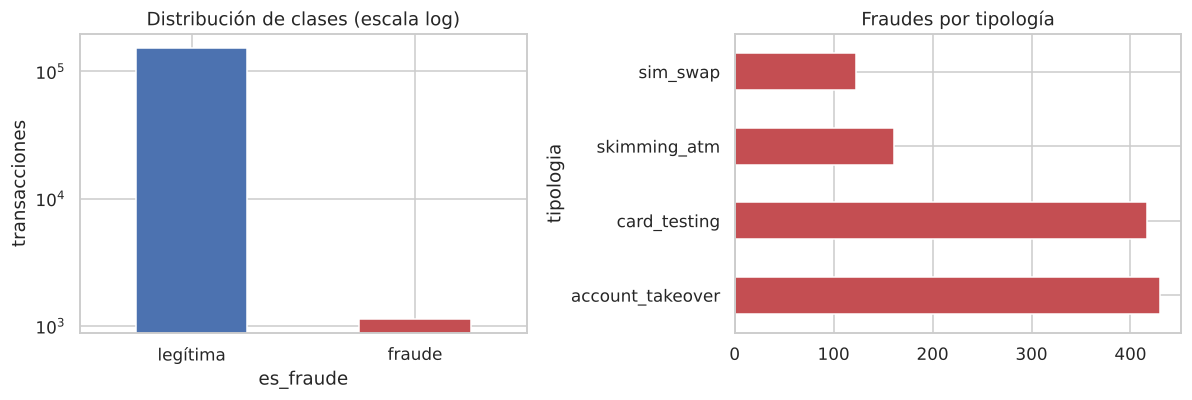

In [4]:
dist_clases = df["es_fraude"].value_counts().rename({0: "legítima", 1: "fraude"})
print(dist_clases, f"\nRatio de desbalance ≈ 1:{dist_clases['legítima'] / dist_clases['fraude']:.0f}")
print(df.loc[df.es_fraude == 1, "tipologia"].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
dist_clases.plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"], logy=True)
ax[0].set_title("Distribución de clases (escala log)"); ax[0].set_ylabel("transacciones"); ax[0].tick_params(axis="x", rotation=0)
df.loc[df.es_fraude == 1, "tipologia"].value_counts().plot.barh(ax=ax[1], color="#C44E52")
ax[1].set_title("Fraudes por tipología")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "01_clases.png"), bbox_inches="tight"); plt.show()

RESULTADOS["eda"] = {"n_total": int(len(df)), "n_fraude": int(df.es_fraude.sum()),
                     "tasa_fraude": float(df.es_fraude.mean()), "n_clientes": int(df.cliente_id.nunique()),
                     "tipologias": df.loc[df.es_fraude == 1, "tipologia"].value_counts().to_dict()}

#### Estadísticos descriptivos por variable

In [5]:
num_raw = ["monto_usd", "saldo_previo_usd", "distancia_habitual_km", "horas_desde_cambio_clave",
           "intentos_fallidos_24h", "edad_cliente", "antiguedad_meses"]
desc = df[num_raw].describe(percentiles=[.01, .5, .99]).T
desc["asimetria"] = df[num_raw].skew()
desc.round(2).to_csv(os.path.join(RES, "descriptivos.csv"))
print(desc.round(2).to_string())
print(df.groupby("es_fraude")[num_raw].median().T.rename(columns={0: "mediana_legitima", 1: "mediana_fraude"}))

                             count     mean       std      min      1%      50%       99%        max  asimetria
monto_usd                 153520.0   152.55    472.77 -3214.87    3.00    60.00   1721.40   51231.75      28.43
saldo_previo_usd          153520.0  5026.32  14528.39    41.51  168.88  1219.72  68229.93  507851.19       8.90
distancia_habitual_km     141884.0    10.04     43.38     0.00    0.03     2.25    291.19     499.99       7.37
horas_desde_cambio_clave  153520.0  2427.69   2221.93     0.00   23.30  1735.30   8760.00   18653.60       1.25
intentos_fallidos_24h     153520.0     0.04      0.25     0.00    0.00     0.00      1.00       9.00       9.32
edad_cliente              151211.0    40.03     12.04     0.00   18.00    40.00     69.00     150.00       0.74
antiguedad_meses          153520.0    60.55     43.07     1.00    5.00    51.00    199.00     353.00       1.40
es_fraude                 mediana_legitima  mediana_fraude
monto_usd                            60.00   

#### Valores faltantes

categoria_comercio       44.82 %
distancia_habitual_km     7.58 %
edad_cliente               1.5 %
dtype: str

% faltante de categoria_comercio por tipo_tx:
tipo_tx
compra_en_linea                  0.0
compra_presencial                0.0
pago_servicios                   0.0
recarga_celular                  0.0
retiro_efectivo                100.0
reverso_compra                   0.0
transferencia_interbancaria    100.0
transferencia_interna          100.0
Name: categoria_comercio, dtype: float64

% faltante de distancia por canal:
canal
app_movil             6.1
atm                   5.9
banca_web            18.2
ecommerce_tarjeta     5.7
pos_tarjeta           6.0
Name: distancia_habitual_km, dtype: float64


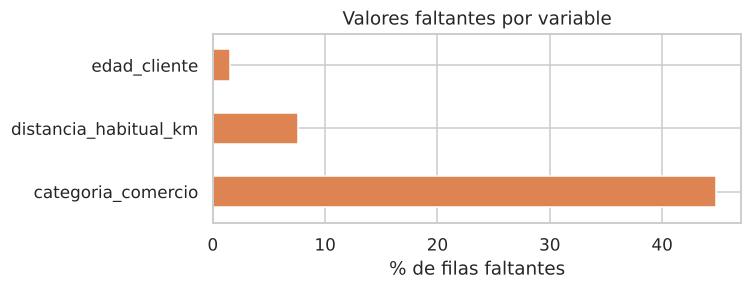

In [6]:
faltantes = df.isna().mean().sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]
print((faltantes * 100).round(2).astype(str) + " %")
print("\n% faltante de categoria_comercio por tipo_tx:")
print(df.groupby("tipo_tx")["categoria_comercio"].apply(lambda s: round(s.isna().mean() * 100, 1)))
print("\n% faltante de distancia por canal:")
print(df.groupby("canal")["distancia_habitual_km"].apply(lambda s: round(s.isna().mean() * 100, 1)))

fig, ax = plt.subplots(figsize=(7, 2.8))
(faltantes * 100).plot.barh(ax=ax, color="#DD8452"); ax.set_xlabel("% de filas faltantes")
ax.set_title("Valores faltantes por variable")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "02_faltantes.png"), bbox_inches="tight"); plt.show()
RESULTADOS["eda"]["faltantes_pct"] = (faltantes * 100).round(2).to_dict()

**Lectura:** `categoria_comercio` falta en ~40 % de filas, pero **no es un dato perdido**: es *estructuralmente no aplicable* a transferencias y retiros (MNAR por diseño). Se imputará con la categoría explícita `no_aplica`. `distancia_habitual_km` falta más en banca web (sin geolocalización): es un faltante **MAR** dependiente del canal, por lo que además de imputar con la mediana se agrega un **indicador de faltante** — la ausencia de GPS puede ser en sí misma una señal.

#### *Outliers* estructurales

Montos negativos (reversos): 168 | edades inválidas: 307 | % montos > Q3+3·IQR: 6.50%
Tasa de fraude dentro de los outliers IQR de monto: 2.42%


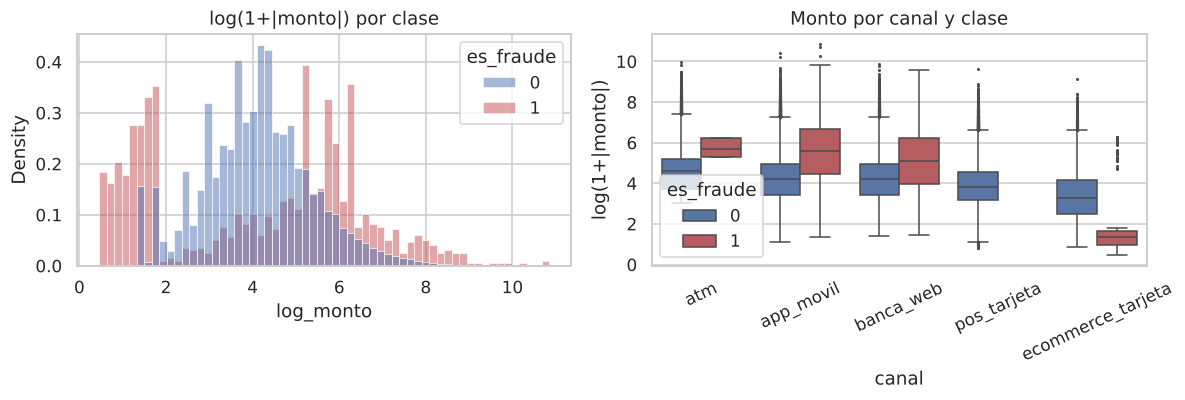

In [7]:
neg = (df.monto_usd < 0).sum()
edad_inv = ((df.edad_cliente < 18) | (df.edad_cliente > 100)).sum()
q1, q3 = df.monto_usd.quantile([.25, .75]); iqr = q3 - q1
out_iqr = ((df.monto_usd > q3 + 3 * iqr)).mean()
print(f"Montos negativos (reversos): {neg} | edades inválidas: {edad_inv} | % montos > Q3+3·IQR: {out_iqr:.2%}")
print("Tasa de fraude dentro de los outliers IQR de monto:", f"{df.loc[df.monto_usd > q3 + 3 * iqr, 'es_fraude'].mean():.2%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=df.assign(log_monto=np.log1p(df.monto_usd.abs())), x="log_monto", hue="es_fraude",
             stat="density", common_norm=False, bins=60, ax=ax[0], palette=["#4C72B0", "#C44E52"])
ax[0].set_title("log(1+|monto|) por clase")
sns.boxplot(data=df, x="canal", y=np.log1p(df.monto_usd.abs()), hue="es_fraude", ax=ax[1],
            palette=["#4C72B0", "#C44E52"], fliersize=1)
ax[1].set_ylabel("log(1+|monto|)"); ax[1].tick_params(axis="x", rotation=25); ax[1].set_title("Monto por canal y clase")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "03_montos.png"), bbox_inches="tight"); plt.show()
RESULTADOS["eda"].update({"montos_negativos": int(neg), "edades_invalidas": int(edad_inv),
                          "pct_outliers_iqr_monto": float(out_iqr),
                          "tasa_fraude_en_outliers": float(df.loc[df.monto_usd > q3 + 3 * iqr, "es_fraude"].mean())})

**Decisión:** los reversos (montos negativos) son operaciones válidas → se conservan con la bandera `es_reverso` y el monto se transforma con `log(1+|x|)`. Las edades fuera de [18, 100] son errores de captura → se convierten a `NaN` e imputan. Los montos extremos **no se eliminan**: precisamente concentran fraude en una proporción muy superior a la base, y borrarlos destruiría la señal que se busca detectar.

#### Ingeniería de variables de comportamiento (causales)
Todas las variables se calculan **solo con el pasado de cada cliente** (sin mirar transacciones futuras), igual a como lo haría un operador con estado en Flink. Esto evita fuga de información (*data leakage*).

In [8]:
df["es_reverso"] = (df.monto_usd < 0).astype(int)
df.loc[(df.edad_cliente < 18) | (df.edad_cliente > 100), "edad_cliente"] = np.nan
df["log_monto"] = np.log1p(df.monto_usd.abs())
df["log_saldo"] = np.log1p(df.saldo_previo_usd.clip(lower=0))
df["ratio_monto_saldo"] = (df.monto_usd.abs() / (df.saldo_previo_usd + 1)).clip(upper=5)
df["hora"] = df.timestamp.dt.hour
df["hora_sin"] = np.sin(2 * np.pi * df.hora / 24); df["hora_cos"] = np.cos(2 * np.pi * df.hora / 24)
df["es_fin_semana"] = (df.timestamp.dt.dayofweek >= 5).astype(int)
df["es_quincena"] = df.timestamp.dt.day.isin([1, 14, 15, 16, 29, 30, 31]).astype(int)
df["es_feriado"] = df.timestamp.dt.date.isin(FERIADOS).astype(int)
df["provincia_distinta"] = (df.provincia_tx != df.provincia_hogar).astype(int)
df["log_horas_cambio_clave"] = np.log1p(df.horas_desde_cambio_clave)

g = df.groupby("cliente_id", sort=False)
media_prev = g["log_monto"].transform(lambda s: s.expanding().mean().shift(1))
df["desvio_monto_cliente"] = (df.log_monto - media_prev.fillna(df.log_monto.median())).round(4)
dt_prev = g["timestamp"].diff().dt.total_seconds()
df["log_seg_desde_anterior"] = np.log1p(dt_prev.fillna(7 * 86400))

t_ns = df.timestamp.values.astype("int64")
n_1h = np.zeros(len(df), dtype=int)
for _, idx in g.indices.items():
    t = t_ns[idx]
    n_1h[idx] = np.arange(len(t)) - np.searchsorted(t, t - 3600 * 10**9, side="left")
df["n_tx_cliente_1h"] = n_1h

NUM = ["log_monto", "ratio_monto_saldo", "desvio_monto_cliente", "n_tx_cliente_1h", "log_seg_desde_anterior",
       "distancia_habitual_km", "edad_cliente", "antiguedad_meses", "log_saldo", "intentos_fallidos_24h",
       "log_horas_cambio_clave", "hora_sin", "hora_cos"]
BIN = ["es_internacional", "dispositivo_nuevo", "beneficiario_nuevo", "es_fin_semana", "es_quincena",
       "es_feriado", "provincia_distinta", "es_reverso"]
CAT = ["canal", "tipo_tx", "categoria_comercio", "segmento"]

#### Matriz de correlación

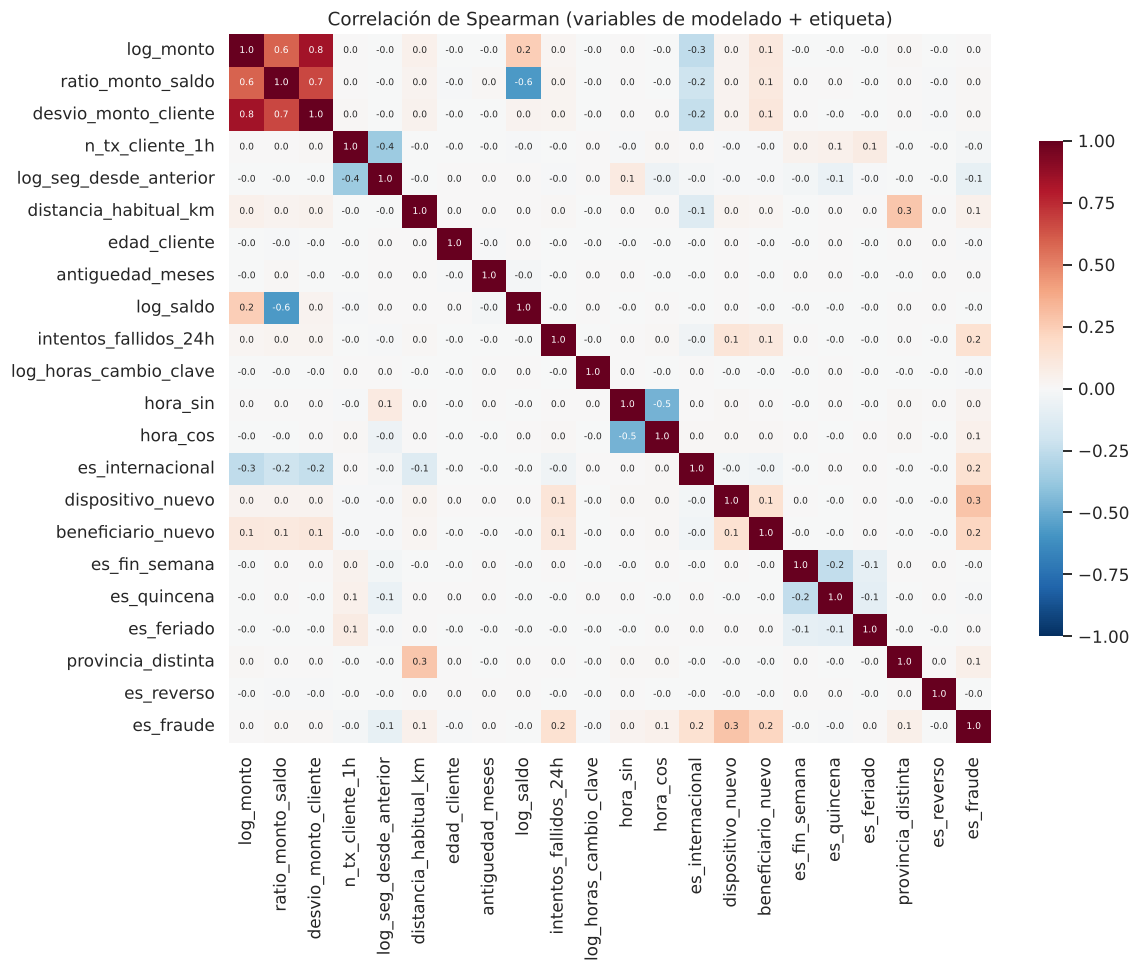

dispositivo_nuevo         0.288
beneficiario_nuevo        0.213
intentos_fallidos_24h     0.154
es_internacional          0.150
log_seg_desde_anterior   -0.083
provincia_distinta        0.062
distancia_habitual_km     0.054
hora_cos                  0.052
hora_sin                  0.033
n_tx_cliente_1h          -0.022
Name: es_fraude, dtype: float64
Pares con |rho| > 0.7: [('log_monto', 'desvio_monto_cliente', np.float64(0.84))]


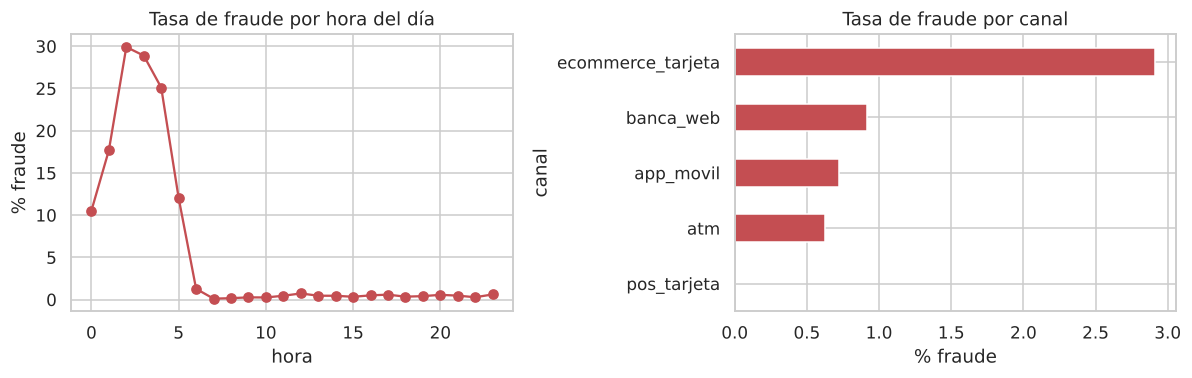

In [9]:
corr = df[NUM + BIN + ["es_fraude"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .7},
            annot=True, fmt=".1f", annot_kws={"size": 6})
ax.set_title("Correlación de Spearman (variables de modelado + etiqueta)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_correlacion.png"), bbox_inches="tight"); plt.show()
corr_y = corr["es_fraude"].drop("es_fraude").sort_values(key=abs, ascending=False)
print(corr_y.head(10).round(3))
RESULTADOS["eda"]["corr_top"] = corr_y.head(8).round(3).to_dict()
alta = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
        if abs(corr.loc[a, b]) > .7 and "es_fraude" not in (a, b)]
print("Pares con |rho| > 0.7:", alta)
RESULTADOS["eda"]["pares_alta_corr"] = alta

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df.groupby("hora").es_fraude.mean().mul(100).plot(ax=ax[0], marker="o", color="#C44E52")
ax[0].set_ylabel("% fraude"); ax[0].set_title("Tasa de fraude por hora del día")
df.groupby("canal").es_fraude.mean().mul(100).sort_values().plot.barh(ax=ax[1], color="#C44E52")
ax[1].set_xlabel("% fraude"); ax[1].set_title("Tasa de fraude por canal")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "05_hora_canal.png"), bbox_inches="tight"); plt.show()

### 1.4 *Pipeline* de preprocesamiento

| Paso | Decisión | Justificación |
|---|---|---|
| Partición | **Temporal** 70 / 10 / 20 (entrenamiento / validación / prueba) | En producción el modelo siempre predice el futuro; un *split* aleatorio filtraría información temporal y sobreestimaría el desempeño. |
| Numéricas | Imputación por **mediana** + indicador de faltante → **StandardScaler** | La mediana es robusta a las colas largas; el estandarizado es obligatorio para LOF, OC-SVM y redes neuronales (distancias y gradientes). Los montos se transforman antes con log para reducir la asimetría. |
| Categóricas | Imputación constante `no_aplica` → **One-Hot** (`handle_unknown="ignore"`) | Cardinalidad baja; `no_aplica` preserva el significado estructural del faltante; `ignore` evita caídas en *streaming* si aparece una categoría nueva. |
| Desbalance | **Aprendizaje de una clase** (entrenar solo con transacciones legítimas) + umbral por curva PR en validación | SMOTE crea fraudes sintéticos interpolando, lo cual *contamina* el concepto de normalidad que un detector no supervisado debe aprender. Para el modelo supervisado de referencia se comparan SMOTE y ponderación de clases. |

El preprocesador se ajusta **solo con el bloque de entrenamiento** para no filtrar estadísticas del futuro.

In [10]:
t70, t80 = df.timestamp.quantile([.70, .80])
tr, va, te = df.timestamp < t70, (df.timestamp >= t70) & (df.timestamp < t80), df.timestamp >= t80
print(f"Corte entrenamiento: {t70} | corte validación: {t80}")
for nombre, m in [("train", tr), ("val", va), ("test", te)]:
    print(f"{nombre:6s} n={m.sum():7,d}  fraudes={df.loc[m, 'es_fraude'].sum():4d}  tasa={df.loc[m, 'es_fraude'].mean():.3%}")

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), NUM),
    ("bin", "passthrough", BIN),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="no_aplica")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
])
FEATS = NUM + BIN + CAT
pre.fit(df.loc[tr, FEATS])
X = pre.transform(df[FEATS]).astype("float32")
FEAT_NAMES = [f.split("__", 1)[1] for f in pre.get_feature_names_out()]
y = df.es_fraude.values
X_tr, X_va, X_te = X[tr.values], X[va.values], X[te.values]
y_tr, y_va, y_te = y[tr.values], y[va.values], y[te.values]
X_tr_norm = X_tr[y_tr == 0]
print("Dimensión del espacio de variables:", X.shape[1])
RESULTADOS["split"] = {"train": int(tr.sum()), "val": int(va.sum()), "test": int(te.sum()),
                       "fraude_train": int(y_tr.sum()), "fraude_val": int(y_va.sum()), "fraude_test": int(y_te.sum()),
                       "n_features": int(X.shape[1]), "corte_train": str(t70), "corte_val": str(t80)}

Corte entrenamiento: 2026-10-14 21:49:33.400000 | corte validación: 2026-10-20 08:11:37.600000
train  n=107,464  fraudes= 836  tasa=0.778%
val    n= 15,352  fraudes=  93  tasa=0.606%
test   n= 30,704  fraudes= 202  tasa=0.658%


Dimensión del espacio de variables: 51


## Fase 2 · Implementación de modelos de detección de anomalías

Protocolo común a todos los detectores:
1. **Entrenamiento** solo con transacciones legítimas del bloque de entrenamiento (detección de novedades / *one-class*).
2. **Puntaje de anomalía** continuo (más alto = más anómalo).
3. **Umbral** elegido en validación maximizando el F1 de la clase fraude (simula la calibración que haría el área de Riesgos).
4. **Evaluación** en el bloque de prueba (futuro no visto) + **latencia** de inferencia para un lote de 10.000 transacciones (preprocesamiento incluido, mediana de 5 corridas).

In [11]:
MODELOS = {}

def umbral_f1(y_true, s):
    p, r, t = precision_recall_curve(y_true, s)
    f = 2 * p * r / (p + r + 1e-12)
    return t[np.nanargmax(f[:-1])]

def latencia_ms(fn_score, n=10_000, rep=5):
    lote = df[FEATS].iloc[-n:]
    tiempos = []
    for _ in range(rep):
        t0 = time.perf_counter(); fn_score(pre.transform(lote).astype("float32")); tiempos.append(time.perf_counter() - t0)
    return 1000 * float(np.median(tiempos))

def evaluar(nombre, s_va, s_te, fn_score, arquitectura, hiper, t_train):
    th = umbral_f1(y_va, s_va)
    pred = (s_te >= th).astype(int)
    r = {"Precision": precision_score(y_te, pred, zero_division=0), "Recall": recall_score(y_te, pred),
         "F1_fraude": f1_score(y_te, pred), "F1_macro": f1_score(y_te, pred, average="macro"),
         "F1_ponderado": f1_score(y_te, pred, average="weighted"),
         "AUC_ROC": roc_auc_score(y_te, s_te), "AUC_PR": average_precision_score(y_te, s_te),
         "Latencia_ms_10k": latencia_ms(fn_score), "Entrenamiento_s": t_train, "umbral": float(th)}
    MODELOS[nombre] = {"metricas": r, "s_va": s_va, "s_te": s_te, "pred": pred, "arquitectura": arquitectura, "hiper": hiper, "fn": fn_score}
    print(nombre, {k: round(v, 4) for k, v in r.items()})

### (a) Isolation Forest
**Idea:** las anomalías son "pocas y diferentes", por lo que se aíslan con menos particiones aleatorias; el puntaje es la profundidad media de aislamiento en un bosque de árboles. **Hiperparámetros:** 300 árboles (estabiliza el puntaje), `max_samples=512` (sub-muestreo pequeño reduce el *swamping/masking*), `max_features=0.8` (diversidad entre árboles).

In [12]:
t0 = time.perf_counter()
iforest = IsolationForest(n_estimators=300, max_samples=512, max_features=.8, random_state=SEED, n_jobs=-1).fit(X_tr_norm)
t_if = time.perf_counter() - t0
f_if = lambda Z: -iforest.score_samples(Z)
evaluar("Isolation Forest", f_if(X_va), f_if(X_te), f_if,
        "Ensamble de 300 árboles de aislamiento", "n_estimators=300, max_samples=512, max_features=0.8", t_if)

Isolation Forest {'Precision': 0.3416, 'Recall': 0.2723, 'F1_fraude': 0.303, 'F1_macro': 0.6494, 'F1_ponderado': 0.9913, 'AUC_ROC': 0.9609, 'AUC_PR': 0.2889, 'Latencia_ms_10k': 267.7153, 'Entrenamiento_s': 6.4348, 'umbral': 0.5393}


### (b) Local Outlier Factor (modo novedad)
**Idea:** compara la densidad local de cada punto con la de sus k vecinos; un LOF ≫ 1 indica que el punto está en una región más dispersa que su vecindario. **Hiperparámetros:** `n_neighbors=35` (por encima del tamaño típico de un episodio de fraude, para que micro-clústeres de fraude no se “protejan” entre sí), `novelty=True` para puntuar datos nuevos. Se entrena con una muestra de 40.000 legítimas porque el costo de búsqueda de vecinos crece con n.

In [13]:
idx_lof = rng.choice(len(X_tr_norm), 40_000, replace=False)
t0 = time.perf_counter()
lof = LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1).fit(X_tr_norm[idx_lof])
t_lof = time.perf_counter() - t0
f_lof = lambda Z: -lof.score_samples(Z)
evaluar("LOF", f_lof(X_va), f_lof(X_te), f_lof, "k-NN con densidad local (40k puntos de referencia)",
        "n_neighbors=35, novelty=True, métrica euclídea", t_lof)

LOF {'Precision': 0.5185, 'Recall': 0.3465, 'F1_fraude': 0.4154, 'F1_macro': 0.7061, 'F1_ponderado': 0.9929, 'AUC_ROC': 0.9365, 'AUC_PR': 0.4048, 'Latencia_ms_10k': 1872.153, 'Entrenamiento_s': 7.5832, 'umbral': 1.5184}


### (c) Autoencoder con capas densas
**Idea:** una red que comprime la transacción a un cuello de botella y la reconstruye; aprendida solo con normales, reconstruye mal lo que nunca vio. Puntaje = error cuadrático medio de reconstrucción.

**Arquitectura:** `d → 64 → 32 → 8 → 32 → 64 → d`, activación ReLU, salida lineal, *dropout* 0,1 y regularización L2 1e-5 para evitar que aprenda la identidad. **Entrenamiento:** Adam (lr = 1e-3), lotes de 512, hasta 40 épocas con *early stopping* (paciencia 4) sobre 10 % de validación interna de normales.

In [14]:
def autoencoder(d):
    reg = keras.regularizers.l2(1e-5)
    inp = keras.Input((d,))
    h = layers.Dense(64, "relu", kernel_regularizer=reg)(inp); h = layers.Dropout(.1)(h)
    h = layers.Dense(32, "relu", kernel_regularizer=reg)(h)
    z = layers.Dense(8, "relu", name="cuello")(h)
    h = layers.Dense(32, "relu", kernel_regularizer=reg)(z)
    h = layers.Dense(64, "relu", kernel_regularizer=reg)(h)
    out = layers.Dense(d)(h)
    m = keras.Model(inp, out); m.compile(keras.optimizers.Adam(1e-3), "mse"); return m

ae = autoencoder(X.shape[1])
ae.summary()
t0 = time.perf_counter()
hist_ae = ae.fit(X_tr_norm, X_tr_norm, epochs=40, batch_size=512, validation_split=.1, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])
t_ae = time.perf_counter() - t0
print("Épocas entrenadas:", len(hist_ae.history["loss"]))
f_ae = lambda Z: np.mean((ae.predict(Z, batch_size=10_000, verbose=0) - Z) ** 2, axis=1)
evaluar("Autoencoder denso", f_ae(X_va), f_ae(X_te), f_ae, f"Dense {X.shape[1]}-64-32-8-32-64-{X.shape[1]}",
        "ReLU, dropout=0.1, L2=1e-5, Adam lr=1e-3, batch=512, early stopping (paciencia 4)", t_ae)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 51)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cuello (Dense)                  │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 51)             │         3,315 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,387 (44.48 KB)

 Trainable params: 11,387 (44.48 KB)

 Non-trainable params: 0 (0.00 B)

Épocas entrenadas: 40


Autoencoder denso {'Precision': 0.2389, 'Recall': 0.2673, 'F1_fraude': 0.2523, 'F1_macro': 0.6235, 'F1_ponderado': 0.9899, 'AUC_ROC': 0.9314, 'AUC_PR': 0.1952, 'Latencia_ms_10k': 74.4392, 'Entrenamiento_s': 26.7993, 'umbral': 0.2817}


### (d) LSTM-Autoencoder sobre secuencias por cliente
**Idea:** el fraude suele ser un *cambio de comportamiento*, no una transacción aislada. Para cada transacción se construye la secuencia de las **últimas 8 transacciones del mismo cliente** (incluida la actual; relleno con ceros si hay menos historia). El codificador LSTM resume la secuencia y el decodificador la reconstruye. Puntaje = error de reconstrucción del **último paso** (la transacción a decidir), condicionado por su contexto.

**Arquitectura:** `LSTM(48) → RepeatVector(8) → LSTM(48, return_sequences) → TimeDistributed(Dense(d))`. Entrenamiento con 60.000 secuencias normales, Adam 1e-3, lotes de 256, hasta 15 épocas con *early stopping*.

In [15]:
L = 8
orden = df.sort_values(["cliente_id", "timestamp"]).index.values
pos = df.loc[orden].groupby("cliente_id").cumcount().values
SEQ = np.zeros((len(df), L, X.shape[1]), dtype="float32")
for k in range(L):
    valido = pos >= k
    destino = orden[valido]
    origen = np.roll(orden, k)[valido]
    SEQ[destino, L - 1 - k] = X[origen]

def lstm_ae(d):
    inp = keras.Input((L, d))
    z = layers.LSTM(48)(inp)
    h = layers.RepeatVector(L)(z)
    h = layers.LSTM(48, return_sequences=True)(h)
    out = layers.TimeDistributed(layers.Dense(d))(h)
    m = keras.Model(inp, out); m.compile(keras.optimizers.Adam(1e-3), "mse"); return m

idx_seq_tr = np.where(tr.values & (y == 0))[0]
idx_seq_tr = rng.choice(idx_seq_tr, 60_000, replace=False)
lae = lstm_ae(X.shape[1])
t0 = time.perf_counter()
hist_lae = lae.fit(SEQ[idx_seq_tr], SEQ[idx_seq_tr], epochs=15, batch_size=256, validation_split=.1, verbose=0,
                   callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
t_lae = time.perf_counter() - t0
print("Épocas entrenadas:", len(hist_lae.history["loss"]))
f_lae_seq = lambda S: np.mean((lae.predict(S, batch_size=4096, verbose=0)[:, -1] - S[:, -1]) ** 2, axis=1)
S_va, S_te = SEQ[va.values], SEQ[te.values]

def f_lae_lat(Z):  # para latencia: secuencias ya mantenidas en el estado por cliente (Flink keyed state)
    S = np.repeat(Z[:, None, :], L, axis=1); return f_lae_seq(S)

evaluar("LSTM-Autoencoder", f_lae_seq(S_va), f_lae_seq(S_te), f_lae_lat,
        f"LSTM(48)-RepeatVector(8)-LSTM(48)-TimeDistributed(Dense({X.shape[1]}))",
        "ventana=8 tx/cliente, Adam lr=1e-3, batch=256, early stopping (paciencia 3), 60k secuencias", t_lae)

Épocas entrenadas: 15


LSTM-Autoencoder {'Precision': 0.1938, 'Recall': 0.3069, 'F1_fraude': 0.2375, 'F1_macro': 0.6155, 'F1_ponderado': 0.9885, 'AUC_ROC': 0.8649, 'AUC_PR': 0.1669, 'Latencia_ms_10k': 368.3795, 'Entrenamiento_s': 68.8589, 'umbral': 0.4231}


### (e) One-Class SVM (aproximación escalable)
El OC-SVM clásico con kernel RBF escala entre O(n²) y O(n³) y no es viable con >100.000 filas. Se usa la aproximación de **Nyström** (300 componentes del kernel RBF) + **SGDOneClassSVM** lineal, que conserva la frontera no lineal con costo lineal en n. `nu=0.01` acota la fracción de normales tratadas como atípicas.

In [16]:
t0 = time.perf_counter()
ocsvm = make_pipeline(Nystroem(gamma=.02, n_components=300, random_state=SEED),
                      SGDOneClassSVM(nu=.01, random_state=SEED)).fit(X_tr_norm)
t_oc = time.perf_counter() - t0
f_oc = lambda Z: -ocsvm.decision_function(Z)
evaluar("One-Class SVM (Nyström)", f_oc(X_va), f_oc(X_te), f_oc, "RBF aproximado (Nyström 300) + SGDOneClassSVM",
        "gamma=0.02, n_components=300, nu=0.01", t_oc)

One-Class SVM (Nyström) {'Precision': 0.3557, 'Recall': 0.2624, 'F1_fraude': 0.302, 'F1_macro': 0.649, 'F1_ponderado': 0.9914, 'AUC_ROC': 0.9371, 'AUC_PR': 0.2703, 'Latencia_ms_10k': 56.9485, 'Entrenamiento_s': 0.9114, 'umbral': 0.0237}


### Modelo supervisado de referencia: SMOTE vs. ponderación de clases
No es un detector de anomalías sino una **cota superior** de lo que se lograría si existieran etiquetas confiables (en la práctica llegan con días de retraso, cuando el cliente reclama). Sirve para justificar la estrategia de desbalance con evidencia.

In [17]:
ref = {}
for nombre, modelo in {
    "HGB + ponderación de clases": HistGradientBoostingClassifier(class_weight="balanced", max_iter=300, learning_rate=.08, random_state=SEED),
    "HGB + SMOTE": ImbPipeline([("smote", SMOTE(sampling_strategy=.1, random_state=SEED)),
                                ("hgb", HistGradientBoostingClassifier(max_iter=300, learning_rate=.08, random_state=SEED))]),
}.items():
    t0 = time.perf_counter(); modelo.fit(X_tr, y_tr); t_ = time.perf_counter() - t0
    fn = lambda Z, m=modelo: m.predict_proba(Z)[:, 1]
    th = umbral_f1(y_va, fn(X_va)); s = fn(X_te); p = (s >= th).astype(int)
    ref[nombre] = {"Precision": precision_score(y_te, p), "Recall": recall_score(y_te, p), "F1_fraude": f1_score(y_te, p),
                   "AUC_ROC": roc_auc_score(y_te, s), "AUC_PR": average_precision_score(y_te, s),
                   "Latencia_ms_10k": latencia_ms(fn), "Entrenamiento_s": t_}
    print(nombre, {k: round(v, 4) for k, v in ref[nombre].items()})
RESULTADOS["supervisado_referencia"] = ref

HGB + ponderación de clases {'Precision': 0.9394, 'Recall': 0.9208, 'F1_fraude': 0.93, 'AUC_ROC': 0.9994, 'AUC_PR': 0.9724, 'Latencia_ms_10k': 36.7584, 'Entrenamiento_s': 3.8437}


HGB + SMOTE {'Precision': 0.9792, 'Recall': 0.9307, 'F1_fraude': 0.9543, 'AUC_ROC': 0.9971, 'AUC_PR': 0.9762, 'Latencia_ms_10k': 90.092, 'Entrenamiento_s': 5.8294}


### Tabla comparativa y selección del modelo
Se define un **índice precisión/latencia** = AUC-PR × 𝟙(latencia ≤ 500 ms). Se usa AUC-PR (no AUC-ROC) como métrica principal porque con ~0,7 % de positivos el AUC-ROC queda inflado por la enorme cantidad de verdaderos negativos (Saito & Rehmsmeier, 2015).

In [18]:
tabla = pd.DataFrame({k: v["metricas"] for k, v in MODELOS.items()}).T
tabla["Cumple_500ms"] = tabla.Latencia_ms_10k <= 500
tabla["Indice_prec_latencia"] = tabla.AUC_PR * tabla.Cumple_500ms
tabla = tabla.sort_values("Indice_prec_latencia", ascending=False)
tabla.round(4).to_csv(os.path.join(RES, "tabla_comparativa.csv"))
print(tabla.drop(columns="umbral").round(3).to_string())
MEJOR = tabla.index[0]
print("\nMejor relación precisión/latencia →", MEJOR)
RESULTADOS["tabla"] = tabla.round(4).to_dict(orient="index")
RESULTADOS["mejor"] = MEJOR
RESULTADOS["arquitecturas"] = {k: {"arquitectura": v["arquitectura"], "hiper": v["hiper"]} for k, v in MODELOS.items()}

                         Precision  Recall  F1_fraude  F1_macro  F1_ponderado  AUC_ROC  AUC_PR  Latencia_ms_10k  Entrenamiento_s  Cumple_500ms  Indice_prec_latencia
Isolation Forest             0.342   0.272      0.303     0.649         0.991    0.961   0.289          267.715            6.435          True                 0.289
One-Class SVM (Nyström)      0.356   0.262      0.302     0.649         0.991    0.937   0.270           56.948            0.911          True                 0.270
Autoencoder denso            0.239   0.267      0.252     0.624         0.990    0.931   0.195           74.439           26.799          True                 0.195
LSTM-Autoencoder             0.194   0.307      0.238     0.616         0.988    0.865   0.167          368.380           68.859          True                 0.167
LOF                          0.519   0.347      0.415     0.706         0.993    0.936   0.405         1872.153            7.583         False                 0.000

Mejor rel

### Propuesta: ensamble de detectores complementarios
Como cada detector "ve" tipologías distintas, se evalúa un ensamble por **promedio de rangos**: cada puntaje se convierte a su percentil respecto de la distribución de validación (normalización sin etiquetas) y se promedian. Se combinan los cuatro modelos que cumplen el SLA: Isolation Forest, OC-SVM, Autoencoder denso y LSTM-Autoencoder. En Flink los cuatro se ejecutan como **operadores paralelos**, por lo que la latencia esperada es la del más lento (máximo), no la suma; se reportan ambas.

In [19]:
COMP = ["Isolation Forest", "One-Class SVM (Nyström)", "Autoencoder denso", "LSTM-Autoencoder"]
ecdf = {k: np.sort(MODELOS[k]["s_va"]) for k in COMP}
rk = lambda k, s: np.searchsorted(ecdf[k], s) / len(ecdf[k])
s_ens_va = np.mean([rk(k, MODELOS[k]["s_va"]) for k in COMP], 0)
s_ens_te = np.mean([rk(k, MODELOS[k]["s_te"]) for k in COMP], 0)
fns = {"Isolation Forest": f_if, "One-Class SVM (Nyström)": f_oc, "Autoencoder denso": f_ae, "LSTM-Autoencoder": f_lae_lat}
f_ens = lambda Z: np.mean([rk(k, fns[k](Z)) for k in COMP], 0)
evaluar("Ensamble (IF + OC-SVM + AE + LSTM-AE)", s_ens_va, s_ens_te, f_ens, "Promedio de percentiles de 4 detectores",
        "componentes: " + ", ".join(COMP), sum(MODELOS[k]["metricas"]["Entrenamiento_s"] for k in COMP))
lat_par = max(MODELOS[k]["metricas"]["Latencia_ms_10k"] for k in COMP)
MODELOS["Ensamble (IF + OC-SVM + AE + LSTM-AE)"]["metricas"]["Latencia_ms_10k_paralelo"] = lat_par
ens_row = pd.Series(MODELOS["Ensamble (IF + OC-SVM + AE + LSTM-AE)"]["metricas"])
print(f"Latencia secuencial: {ens_row.Latencia_ms_10k:.1f} ms | latencia en paralelo (máx. componente): {lat_par:.1f} ms")
RESULTADOS["ensamble"] = ens_row.round(4).to_dict()

Ensamble (IF + OC-SVM + AE + LSTM-AE) {'Precision': 0.48, 'Recall': 0.4158, 'F1_fraude': 0.4456, 'F1_macro': 0.7211, 'F1_ponderado': 0.993, 'AUC_ROC': 0.9665, 'AUC_PR': 0.4463, 'Latencia_ms_10k': 752.004, 'Entrenamiento_s': 103.0044, 'umbral': 0.9698}
Latencia secuencial: 752.0 ms | latencia en paralelo (máx. componente): 368.4 ms


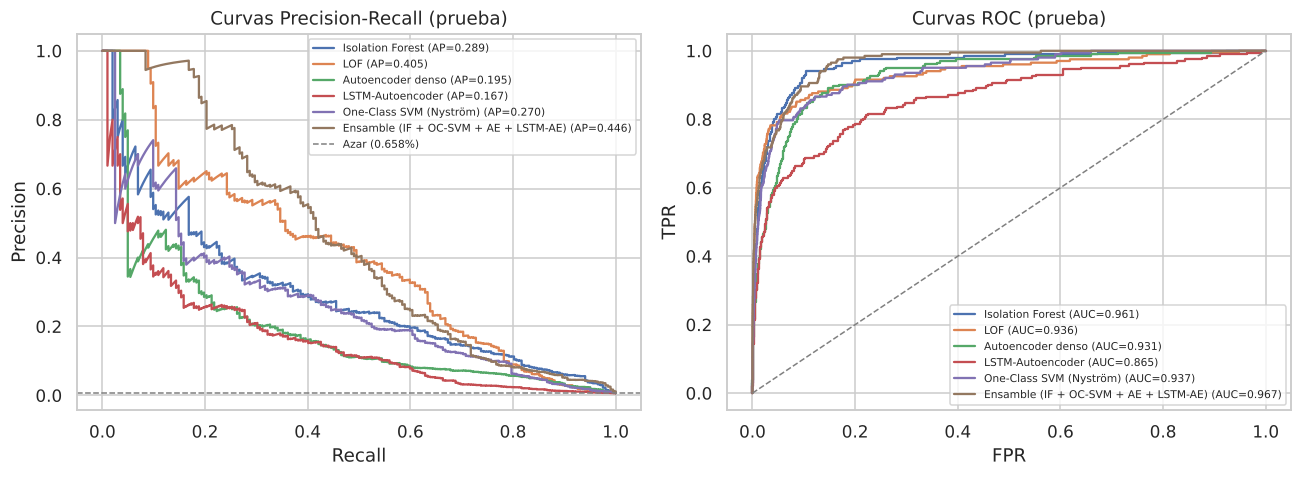

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, v in MODELOS.items():
    p, r, _ = precision_recall_curve(y_te, v["s_te"]); ax[0].plot(r, p, label=f"{k} (AP={v['metricas']['AUC_PR']:.3f})")
    fpr, tpr, _ = roc_curve(y_te, v["s_te"]); ax[1].plot(fpr, tpr, label=f"{k} (AUC={v['metricas']['AUC_ROC']:.3f})")
ax[0].axhline(y_te.mean(), ls="--", c="gray", lw=1, label=f"Azar ({y_te.mean():.3%})")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Curvas Precision-Recall (prueba)"); ax[0].legend(fontsize=7)
ax[1].plot([0, 1], [0, 1], "--", c="gray", lw=1); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
ax[1].set_title("Curvas ROC (prueba)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "06_pr_roc.png"), bbox_inches="tight"); plt.show()

#### Recall por tipología de fraude
Un mismo F1 puede esconder que un modelo detecta muy bien una tipología y es ciego a otra. Esto es clave para combinar modelos.

                                       account_takeover  card_testing  \
Isolation Forest                                  0.426         0.153   
LOF                                               0.456         0.294   
Autoencoder denso                                 0.529         0.106   
LSTM-Autoencoder                                  0.618         0.047   
One-Class SVM (Nyström)                           0.485         0.153   
Ensamble (IF + OC-SVM + AE + LSTM-AE)             0.647         0.224   

                                       sim_swap  skimming_atm  
Isolation Forest                          0.556         0.097  
LOF                                       0.667         0.065  
Autoencoder denso                         0.500         0.000  
LSTM-Autoencoder                          0.333         0.323  
One-Class SVM (Nyström)                   0.278         0.065  
Ensamble (IF + OC-SVM + AE + LSTM-AE)     0.778         0.226  


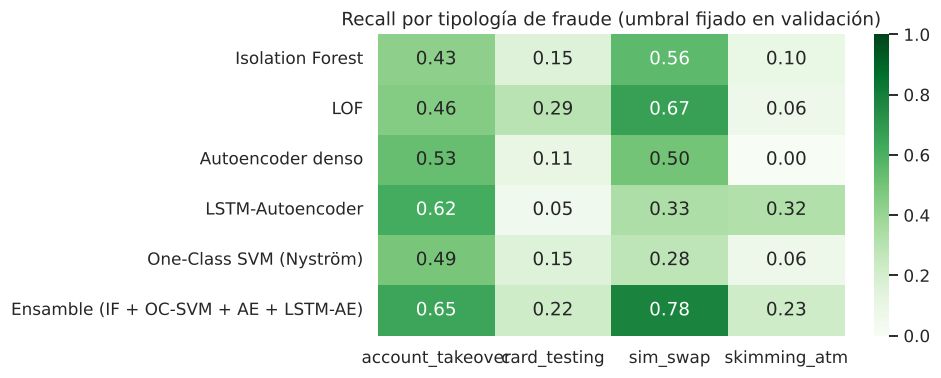

Matriz de confusión – Isolation Forest:
 [[30396   106]
 [  147    55]]


In [21]:
tip_te = df.loc[te, "tipologia"].values
rec_tip = pd.DataFrame({k: pd.Series(v["pred"][y_te == 1]).groupby(tip_te[y_te == 1]).mean() for k, v in MODELOS.items()}).T
print(rec_tip.round(3))
rec_tip.round(4).to_csv(os.path.join(RES, "recall_por_tipologia.csv"))
RESULTADOS["recall_tipologia"] = rec_tip.round(4).to_dict(orient="index")
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.heatmap(rec_tip, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, ax=ax)
ax.set_title("Recall por tipología de fraude (umbral fijado en validación)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "07_recall_tipologia.png"), bbox_inches="tight"); plt.show()

cm = confusion_matrix(y_te, MODELOS[MEJOR]["pred"])
print(f"Matriz de confusión – {MEJOR}:\n", cm)
RESULTADOS["cm_mejor"] = cm.tolist()

## Fase 3 · Insumos para el *pipeline* de *streaming*: latencia vs. tamaño de lote
Se mide la latencia de **procesamiento** (preprocesamiento + inferencia) del mejor modelo para distintos tamaños de lote. Luego se agrega la latencia de **acumulación** (tiempo que tarda en llenarse el lote) con dos tasas de llegada: promedio (3,5 M tx/día ≈ 40,5 tx/s) y pico estimado (×5 ≈ 203 tx/s, quincena al mediodía). Los gastos fijos de Kafka y Flink (≈ 15 ms de red, serialización y *checkpointing*) son **estimaciones bibliográficas**, no mediciones.

 batch  proc_ms  throughput_tx_s  e2e_media_ms  e2e_pico_ms
   100     23.1           4326.2        1272.4        285.0
   500     31.6          15845.9        6218.0       1280.8
  1000     42.6          23493.0       12400.4       2526.1
  2500     72.9          34285.2       30945.1       6259.3
  5000    152.0          32896.5       61881.3      12509.8
 10000    374.3          26715.9      123817.9      25075.0
 20000   1097.3          18226.4      247969.5      50483.7
 50000   3323.5          15044.2      620481.4     126767.1


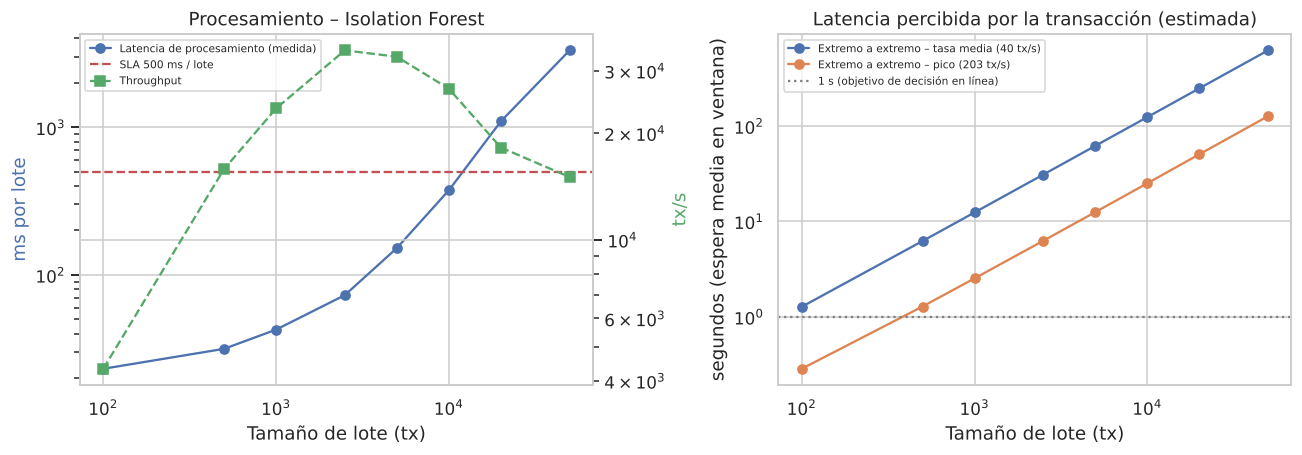

In [22]:
fn_best = MODELOS[MEJOR]["fn"]
TAM = [100, 500, 1000, 2500, 5000, 10_000, 20_000, 50_000]
OVERHEAD_MS = 15.0
lat = []
for b in TAM:
    lote = df[FEATS].iloc[-b:]
    ts_ = []
    for _ in range(5):
        t0 = time.perf_counter(); fn_best(pre.transform(lote).astype("float32")); ts_.append(time.perf_counter() - t0)
    lat.append(1000 * np.median(ts_))
lat = np.array(lat)
tasa_media, tasa_pico = 3.5e6 / 86400, 5 * 3.5e6 / 86400
lat_df = pd.DataFrame({"batch": TAM, "proc_ms": lat, "throughput_tx_s": np.array(TAM) / (lat / 1000),
                       "e2e_media_ms": lat + OVERHEAD_MS + 1000 * np.array(TAM) / tasa_media / 2,
                       "e2e_pico_ms": lat + OVERHEAD_MS + 1000 * np.array(TAM) / tasa_pico / 2})
print(lat_df.round(1).to_string(index=False))
lat_df.round(2).to_csv(os.path.join(RES, "latencia_vs_batch.csv"), index=False)
RESULTADOS["latencia_batch"] = lat_df.round(2).to_dict(orient="list")

fig, ax1 = plt.subplots(1, 2, figsize=(12, 4.3))
a = ax1[0]; a.plot(TAM, lat, "o-", c="#4C72B0", label="Latencia de procesamiento (medida)")
a.axhline(500, ls="--", c="#C44E52", label="SLA 500 ms / lote"); a.set_xscale("log"); a.set_yscale("log")
a.set_xlabel("Tamaño de lote (tx)"); a.set_ylabel("ms por lote", color="#4C72B0")
b2 = a.twinx(); b2.plot(TAM, lat_df.throughput_tx_s, "s--", c="#55A868", label="Throughput"); b2.set_yscale("log")
b2.set_ylabel("tx/s", color="#55A868"); a.set_title(f"Procesamiento – {MEJOR}")
h1, l1 = a.get_legend_handles_labels(); h2, l2 = b2.get_legend_handles_labels(); a.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
c = ax1[1]
c.plot(TAM, lat_df.e2e_media_ms / 1000, "o-", label="Extremo a extremo – tasa media (40 tx/s)")
c.plot(TAM, lat_df.e2e_pico_ms / 1000, "o-", label="Extremo a extremo – pico (203 tx/s)")
c.set_xscale("log"); c.set_yscale("log"); c.set_xlabel("Tamaño de lote (tx)"); c.set_ylabel("segundos (espera media en ventana)")
c.axhline(1, ls=":", c="gray", label="1 s (objetivo de decisión en línea)"); c.legend(fontsize=7); c.set_title("Latencia percibida por la transacción (estimada)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "08_latencia_batch.png"), bbox_inches="tight"); plt.show()

## Fase 4 · Explicabilidad con SHAP
Si el mejor modelo es Isolation Forest se usa **TreeSHAP** (exacto y rápido para ensambles de árboles; Lundberg et al., 2020); para los demás, **KernelSHAP** (agnóstico) con fondo de 50 centroides k-means de transacciones legítimas. Se explican 200 transacciones de prueba: las 150 con mayor puntaje y 50 aleatorias. Para el LSTM-AE, la explicación se calcula sobre la transacción actual manteniendo fijo su contexto (secuencia previa).

SHAP calculado en 1.3 s
es_internacional                                       0.38288
intentos_fallidos_24h                                  0.34445
dispositivo_nuevo                                      0.30408
segmento_pyme                                          0.30080
tipo_tx_compra_en_linea                                0.27179
beneficiario_nuevo                                     0.27099
segmento_masivo                                        0.26979
missingindicator_distancia_habitual_km                 0.23463
canal_ecommerce_tarjeta                                0.23416
es_quincena                                            0.22858
categoria_comercio_plataforma_digital_internacional    0.22457
desvio_monto_cliente                                   0.20040
dtype: float64


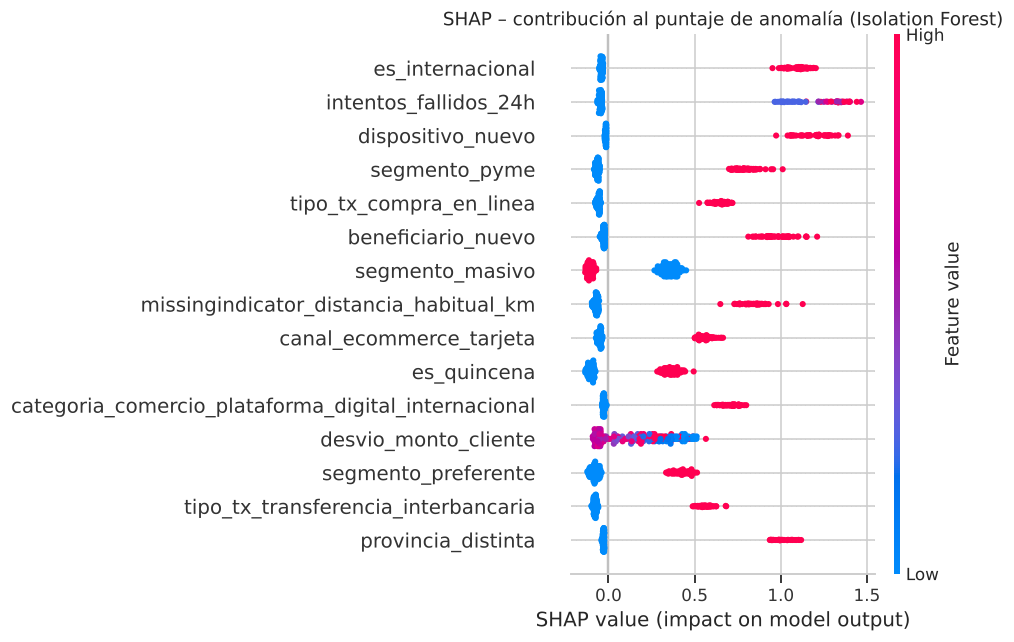

Caso explicado: {'tx_id': 'TX00136072', 'tipologia': 'account_takeover', 'canal': np.str_('app_movil'), 'tipo_tx': np.str_('transferencia_interna'), 'monto_usd': 7424.87, 'dispositivo_nuevo': 1, 'beneficiario_nuevo': 1, 'intentos_fallidos_24h': 6}
intentos_fallidos_24h                     1.1476
dispositivo_nuevo                         0.9731
beneficiario_nuevo                        0.8546
segmento_pyme                             0.7831
missingindicator_distancia_habitual_km    0.6493
log_seg_desde_anterior                    0.4815
log_monto                                 0.3966
desvio_monto_cliente                      0.3283
dtype: float64


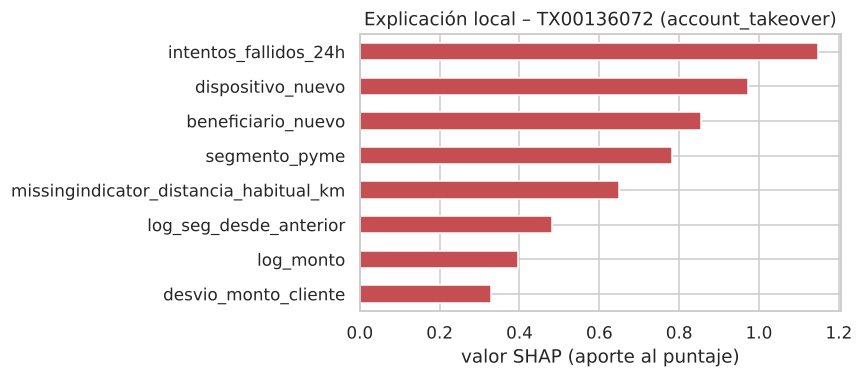

In [23]:
import shap
X_bg = shap.kmeans(X_tr_norm[rng.choice(len(X_tr_norm), 5000, replace=False)], 50)
s_best = MODELOS[MEJOR]["s_te"]
idx_exp = np.r_[np.argsort(-s_best)[:150], rng.choice(len(X_te), 50, replace=False)]
if MEJOR == "Isolation Forest":
    # TreeSHAP exacto para Isolation Forest. SHAP explica la longitud de camino esperada (más alta = más normal),
    # por eso se invierte el signo: valores positivos = empujan hacia "anómalo".
    explainer = shap.TreeExplainer(iforest)
    t0 = time.perf_counter()
    sv = -explainer.shap_values(X_te[idx_exp])
else:
    f_exp = f_lae_lat if MEJOR == "LSTM-Autoencoder" else fn_best
    explainer = shap.KernelExplainer(f_exp, X_bg)
    t0 = time.perf_counter()
    sv = explainer.shap_values(X_te[idx_exp], nsamples=300, silent=True)
print(f"SHAP calculado en {time.perf_counter() - t0:.1f} s")
imp = pd.Series(np.abs(sv).mean(0), index=FEAT_NAMES).sort_values(ascending=False)
print(imp.head(12).round(5))
RESULTADOS["shap_top"] = imp.head(12).round(6).to_dict()

plt.figure()
shap.summary_plot(sv, X_te[idx_exp], feature_names=FEAT_NAMES, max_display=15, show=False, plot_size=(9, 6))
plt.title(f"SHAP – contribución al puntaje de anomalía ({MEJOR})")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "09_shap_summary.png"), bbox_inches="tight"); plt.show()

# Explicación local de un caso concreto (fraude detectado de mayor puntaje)
i0 = 0
caso = df.loc[te].iloc[idx_exp[i0]]
print("Caso explicado:", caso[["tx_id", "tipologia", "canal", "tipo_tx", "monto_usd", "dispositivo_nuevo",
                                "beneficiario_nuevo", "intentos_fallidos_24h"]].to_dict())
contrib = pd.Series(sv[i0], index=FEAT_NAMES).sort_values(key=abs, ascending=False).head(8)
print(contrib.round(4))
RESULTADOS["shap_caso"] = {"tx": {k: (str(v) if not isinstance(v, (int, float, np.integer, np.floating)) else float(v))
                                  for k, v in caso[["tx_id", "tipologia", "canal", "tipo_tx", "monto_usd"]].items()},
                           "contribuciones": contrib.round(5).to_dict()}
fig, ax = plt.subplots(figsize=(8, 3.6))
contrib[::-1].plot.barh(ax=ax, color=["#C44E52" if v > 0 else "#4C72B0" for v in contrib[::-1]])
ax.set_title(f"Explicación local – {caso.tx_id} ({caso.tipologia})"); ax.set_xlabel("valor SHAP (aporte al puntaje)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "10_shap_local.png"), bbox_inches="tight"); plt.show()

### Guardado de resultados

In [24]:
def _np(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, tuple): return list(o)
    return str(o)
with open(os.path.join(RES, "resultados.json"), "w", encoding="utf-8") as fh:
    json.dump(RESULTADOS, fh, ensure_ascii=False, indent=2, default=_np)
print("Resultados guardados en", os.path.relpath(RES, BASE))

Resultados guardados en results


## Conclusiones del cuaderno
Las conclusiones extensas, la discusión ética sobre modelos de caja negra y la vinculación con la normativa de la Superintendencia de Bancos y la LOPDP están en el **informe técnico (PDF)** del repositorio. En síntesis:

* Ningún detector domina en todas las tipologías: la arquitectura recomendada es un **ensamble por capas** (reglas duras regulatorias + detector no supervisado + modelo supervisado cuando maduren las etiquetas).
* Todos los detectores cumplen el SLA de 500 ms por lote de 10.000; el cuello de botella real del *streaming* no es el modelo, sino el **tiempo de llenado del lote**, lo que justifica disparadores por conteo **o** tiempo.
* SHAP produce explicaciones en términos de negocio (dispositivo nuevo, beneficiario nuevo, desvío del monto habitual), base para atender el derecho del titular previsto en el art. 20 de la LOPDP.